# 08-无线OTA系统设计与状态机框架


## 1. 本篇范围与学习目标

第07篇已经把OneNET的产品、设备、升级任务和HTTP接口串起来。本篇开始让GD32接管ESP32-C3：把“能在串口工具里发命令”推进到“有接线、有存储布局、有交互、有状态流转的App工程”。

本篇对应讲义《OTA远程升级》物理页70—74，视频32—36：

| 视频 | 最后字幕时间 | 内容 |
|---|---:|---|
| 32 无线OTA_开发板接线方式 | 01:45 | GD32与ESP32-C3的UART、复位和共地 |
| 33 无线OTA_有限状态机FSM&OTA升级状态图 | 09:00 | FSM概念，App与Bootloader的分工 |
| 34 无线OTA_外置Flash VS 内置Flash方案 | 04:44 | 固件暂存位置、容量与分区 |
| 35 无线OTA_OLED屏幕和按键配合 | 11:58 | 当前版本、新版本、大小、按键模拟与升级入口 |
| 36 无线OTA_App状态机主流程搭建及测试 | 15:23 | 六个主状态、三态返回值、失败回退与桩函数验证 |

**本篇完成的是系统设计和App主状态机框架。** 各AT命令的发送接收、联网子状态、真实JSON解析留到09；Bootloader分片下载、校验和替换固件留到10。不要把本篇中返回OK的模拟函数当成已经实现联网。

资料来自[课程网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。正文依据五段视频的完整自动字幕、讲义原图及配套 `Code.zip` 的App/Bootloader源码整理；字幕中的函数名按源码校正。没有逐帧完整观看视频，**未进行开发板烧录、Keil编译或硬件联调**。下文的测试结果是课程演示现象和按代码推导的预期，均不冒充本机实测。


## 2. 开发板接线：两根串口线、一根复位线和共地

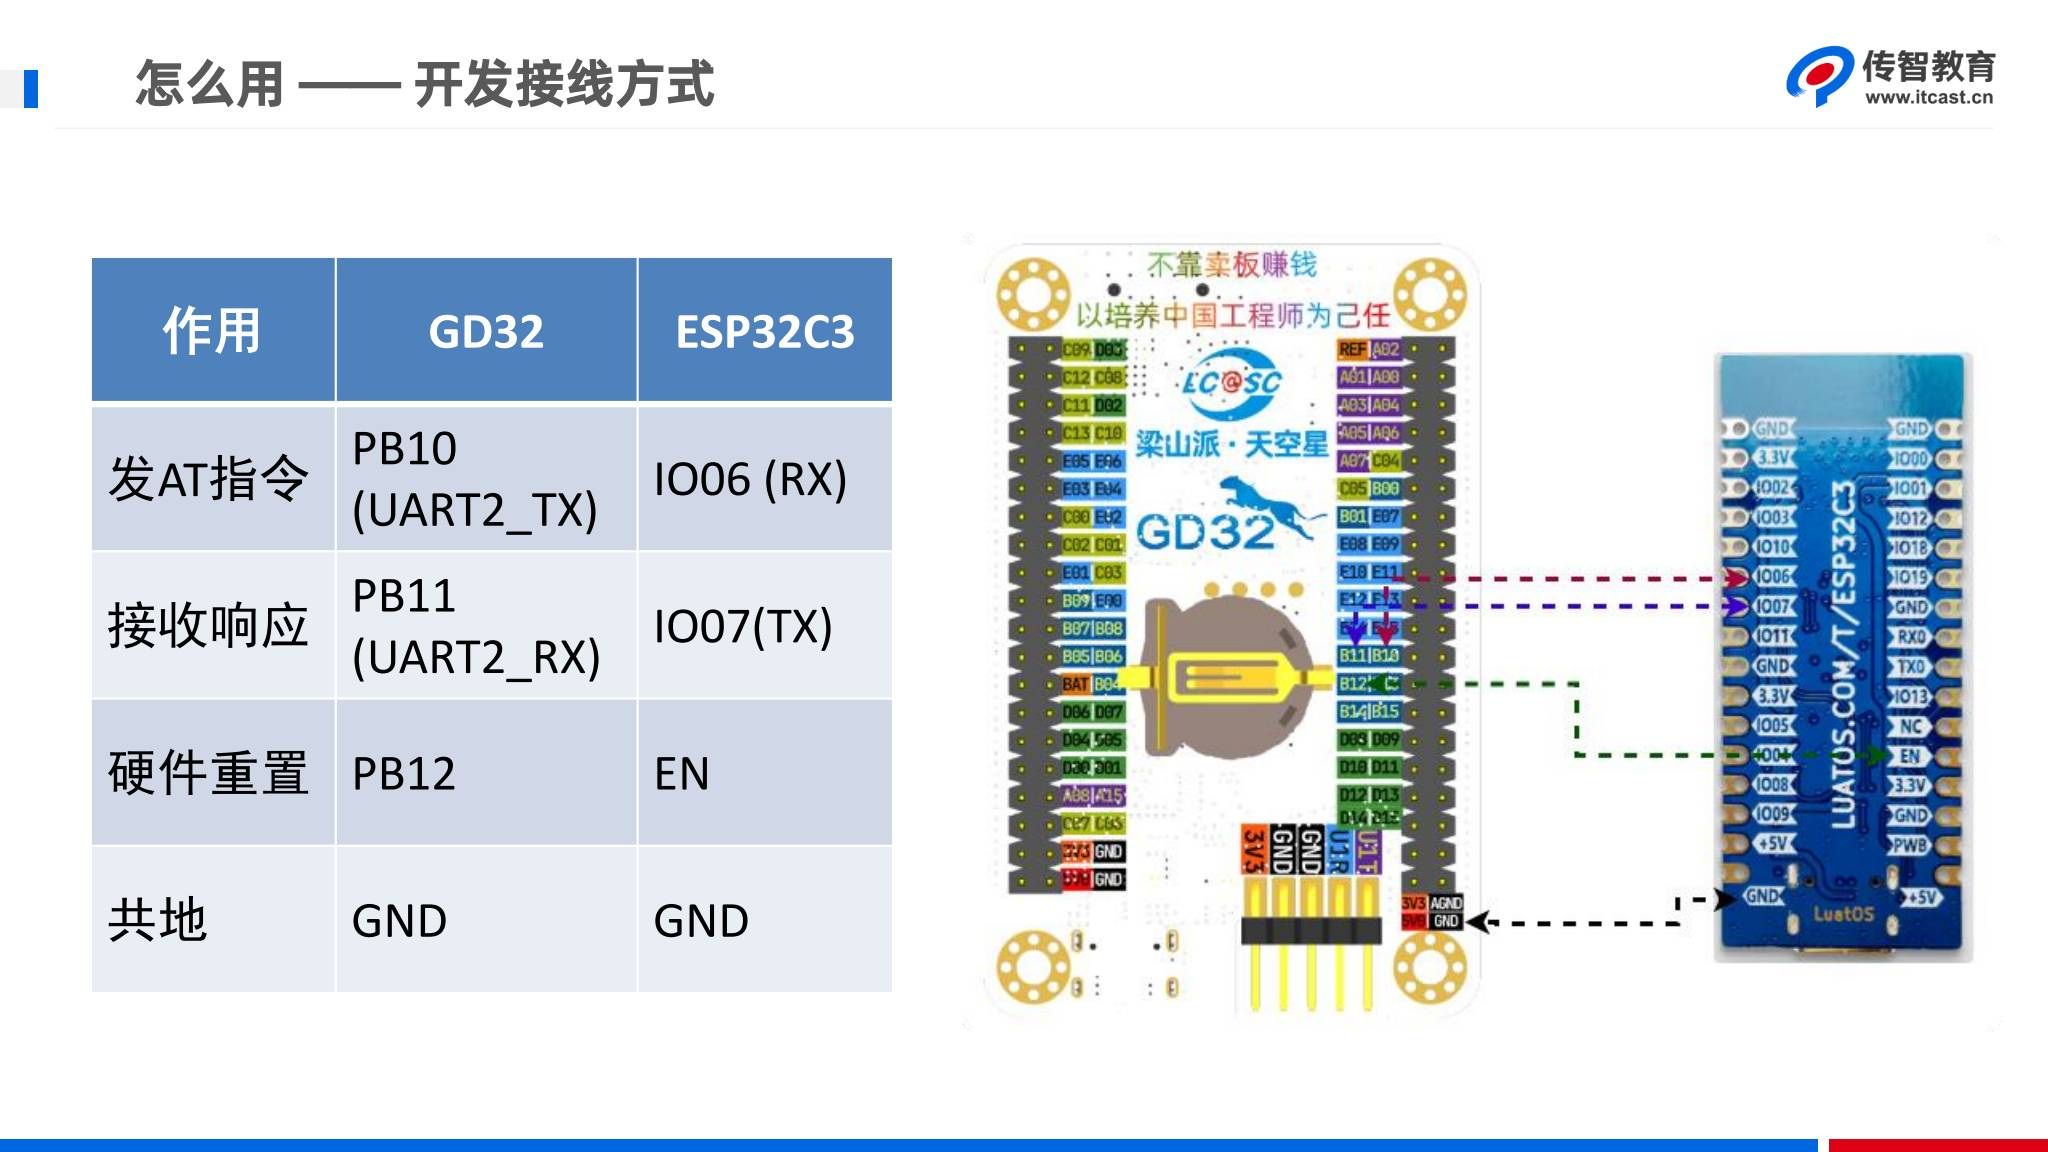

*讲义第70页。以左侧管脚表为准：PB10接IO6，PB11接IO7，PB12接EN，两板共地。*

| 作用 | GD32F407 | 方向 | ESP32-C3 |
|---|---|---|---|
| 主控发送AT指令 | PB10，USART2_TX | GD32 → ESP | IO6，AT UART RX |
| 主控接收响应 | PB11，USART2_RX | ESP → GD32 | IO7，AT UART TX |
| 硬件复位 | PB12，GPIO输出 | GD32 → ESP | EN |
| 公共参考地 | GND | 两板连接 | GND |

接线的判断方法是看**信号方向**：发送端TX接对方RX，不能因为两块板都印有TX就直接同名相连。这里使用ESP32-C3运行ESP-AT固件时的命令串口IO6/7；其下载日志口GPIO20/21在第06篇已经区分。

课程中两块开发板各自通过USB供电，板间再接以上四根线。视频里的“四根线”不包含额外的板间供电线。独立供电时仍必须共地；实际板型不同时，先核对3.3 V逻辑电平、管脚复用和电源方案。

建议按以下次序排线：

1. 断电，接GND。
2. 接PB10 → IO6、PB11 ← IO7。
3. 接PB12 → EN，确认不是接到ESP的BOOT下载按键引脚。
4. 两板供电，确认ESP已经烧入第06篇所用的ESP-AT固件。
5. 检查GD32工程USART2配置、波特率和接收通路，再排查上层状态机。

**USART2是GD32工程的外设命名。** 不要在移植时机械地把它当成其他芯片HAL里的USART2或第二个串口；以当前芯片手册和工程管脚配置为准。


## 3. EN硬件复位与AT软复位的职责

App首先尝试通过AT串口让模块恢复工作；串口命令无法得到合理响应时，才需要主控操作EN。

| 操作 | 方式 | 使用场景 |
|---|---|---|
| AT软复位 | `AT+RST\r\n` | 模块串口仍可用，重新启动ESP-AT |
| 硬件复位 | PB12把EN拉低，再恢复高电平 | 模块无响应、需要从硬件恢复 |
| GD32系统复位 | 写升级标志后复位主控 | 从App重新进入Bootloader |

配套 `Common/wifi_drv.c` 的 `HwresetWifiModule()` 做法是：

```text
EN拉低 → delay_1ms(100) → EN拉高 → ESP重新启动
```

100 ms低电平是课堂驱动的实现值。拉高只是释放复位，不能据此认定模块已经可以收下一条HTTP命令；后续模块检查还要等待启动完成和期望响应。

`App_Wifi_Init()` 调用 `InitSysParam()` 和 `WifiModuleDrvInit()`。后者初始化PB12等驱动资源，并包含一次初始化复位。主状态机中的“三次硬件复位机会”是**进入恢复分支之后的计数**，不包括这次初始化动作。

源码里 `WifiUartInit()`、`WifiDmaInit()` 仍是空壳，不能把这些函数名当成UART/DMA已经完成配置的证据。配套工程的USART初始化位于主程序和Library/USART配置中，USART2使用115200波特率，接收配置也要沿实际库文件检查。


## 4. FSM：把耗时流程拆成能反复推进的小步骤

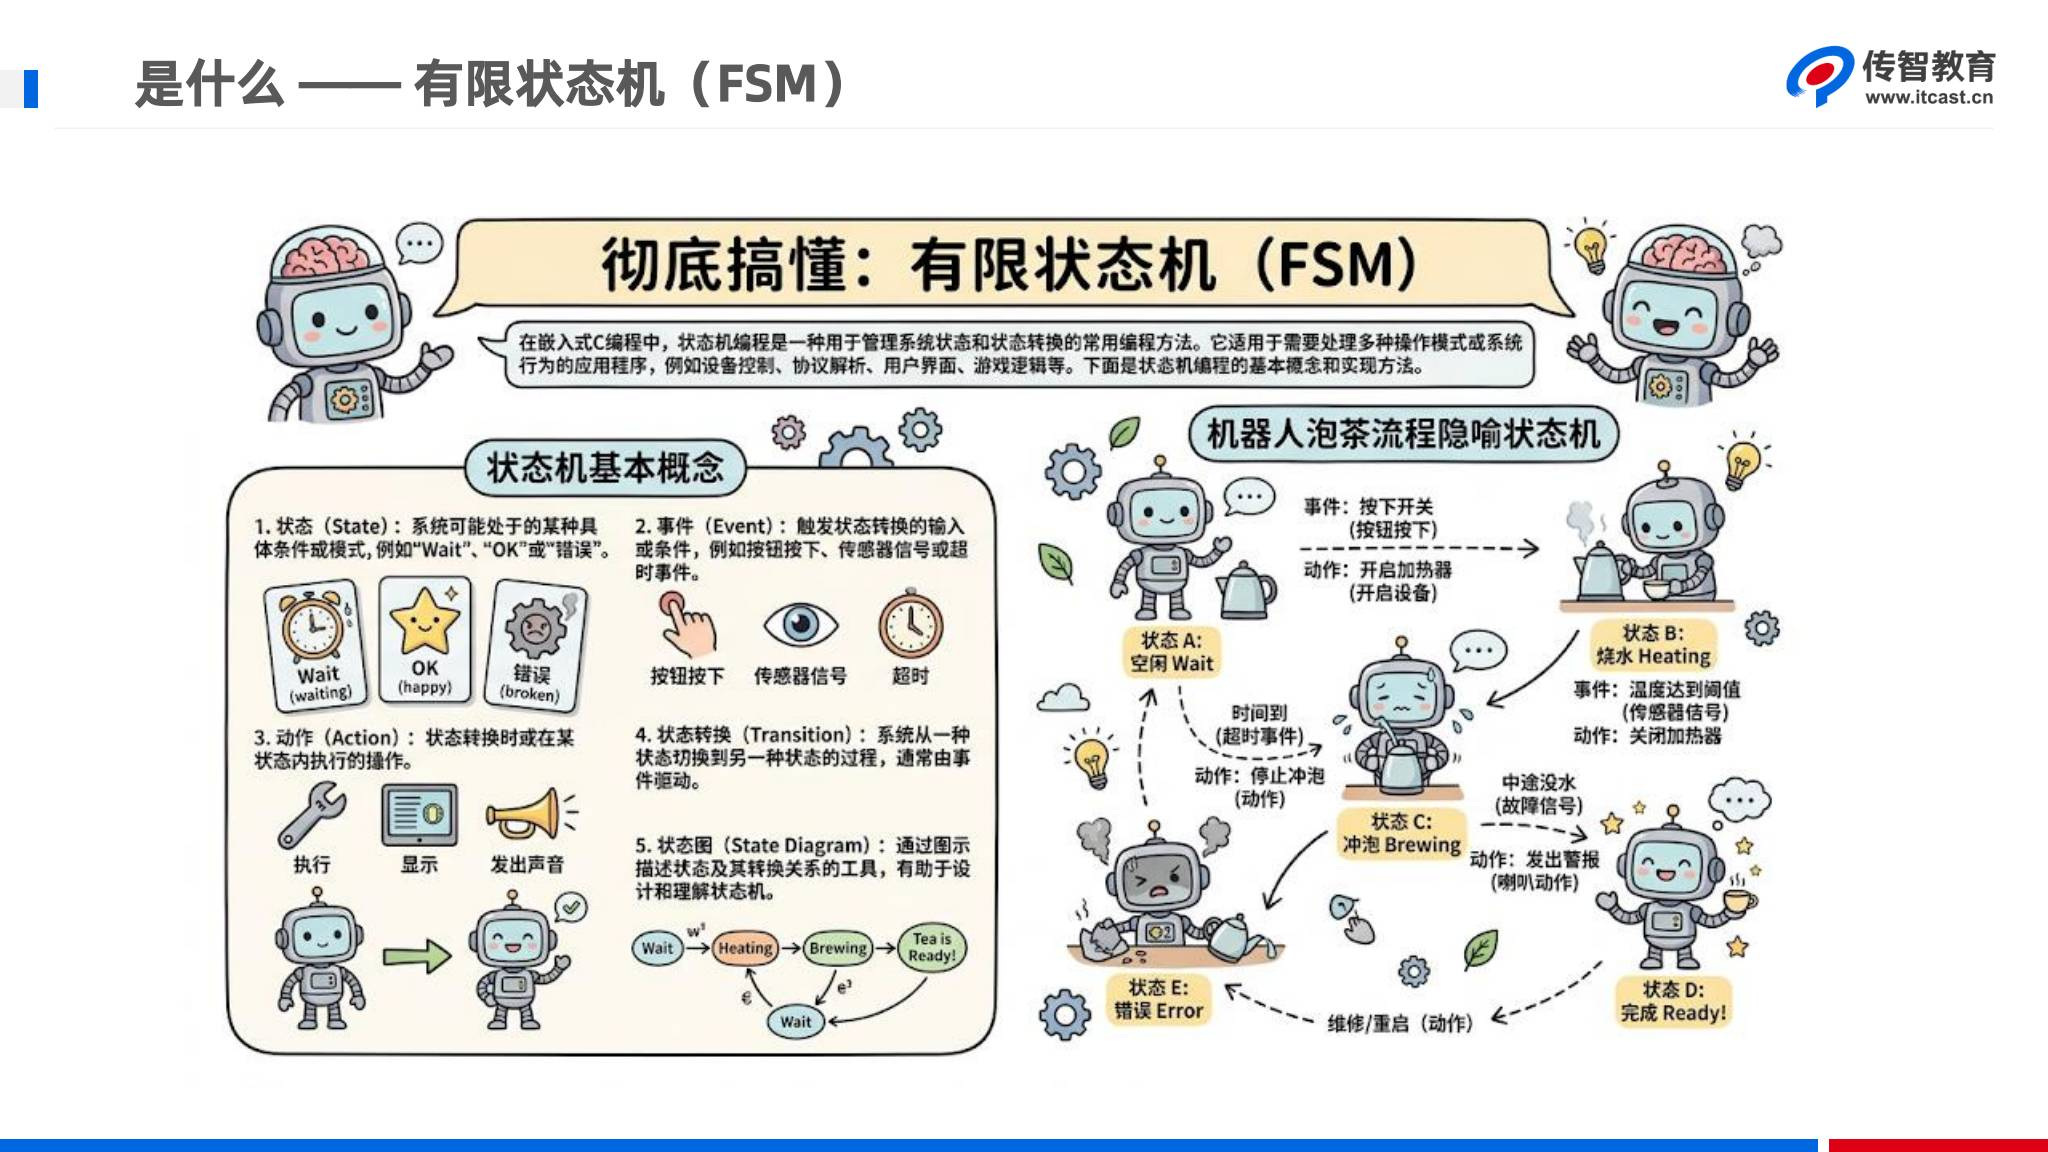

*讲义第71页，用有限状态机描述设备在不同条件下的行为。*

有限状态机（Finite State Machine，FSM）用有限个状态和明确的转换规则组织业务。本课最有用的五个概念是：

| 概念 | 含义 | OTA例子 |
|---|---|---|
| 状态 State | 当前在做哪一阶段 | 检查模块、联网、获取升级信息 |
| 事件 Event | 促使程序判断下一步的输入 | 收到OK、超时、按键长按 |
| 动作 Action | 在状态内或转换时执行的操作 | 发AT指令、拉低EN、写升级标志 |
| 转换 Transition | 从一个状态转到另一个状态 | 联网成功后进入版本检测 |
| 状态图 State Diagram | 把状态及转换条件画出来 | App图和Bootloader图 |

例如：

```text
检查模块
  ├─ 成功 → 检查Wi-Fi连接
  ├─ 等待 → 留在当前状态，下次继续
  └─ 失败 → 尝试硬件复位
```

状态机适合这里，是因为“发出一条命令”和“网络结果回来”并不发生在同一瞬间。每次任务回调只推进一点，其他时间继续运行屏幕刷新、按键扫描等任务，避免用一个长while一直等串口结果。

本课采用 `enum + static状态变量 + switch` 的C语言写法。状态图描述规则，代码实现规则；不能只照着图写几个case，却忽略每条成功、等待、失败边。


## 5. App与Bootloader的分工：用户确认前后是两条链路

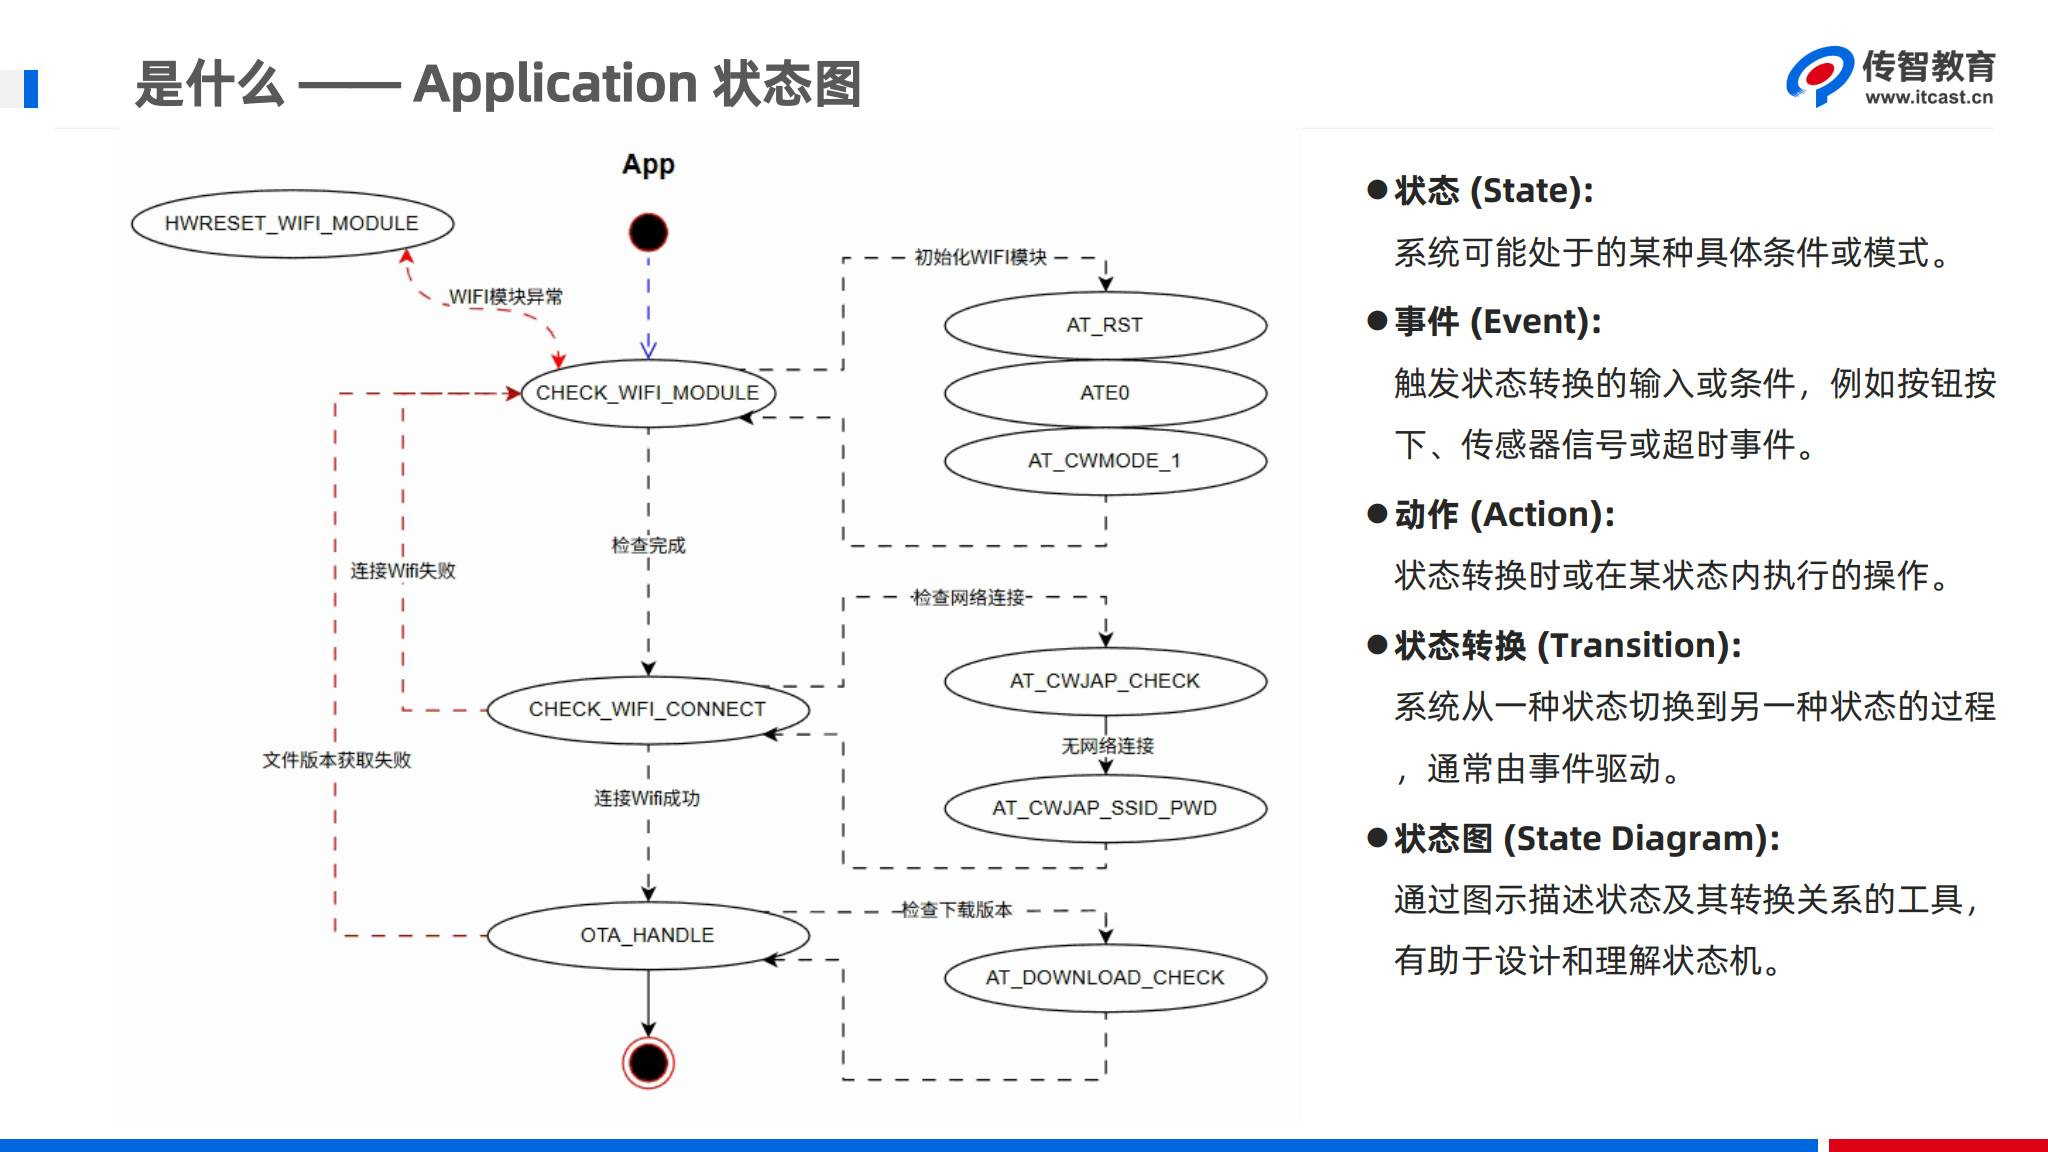

*讲义第72页：主状态负责阶段推进，虚线框中的子状态负责一组具体AT操作。*

App主要承担：

```text
检查ESP模块
  → 检查或建立Wi-Fi连接
  → 查询是否有升级任务
  → 保存目标版本、文件大小等信息
  → OLED提示
  → 等待用户长按确认
  → 写升级标志，复位进入Bootloader
```

App发现新版本时，通常仍有自己的业务在运行。本课让用户确认后才进入升级流程，避免检测到新版本就立即覆盖当前程序。

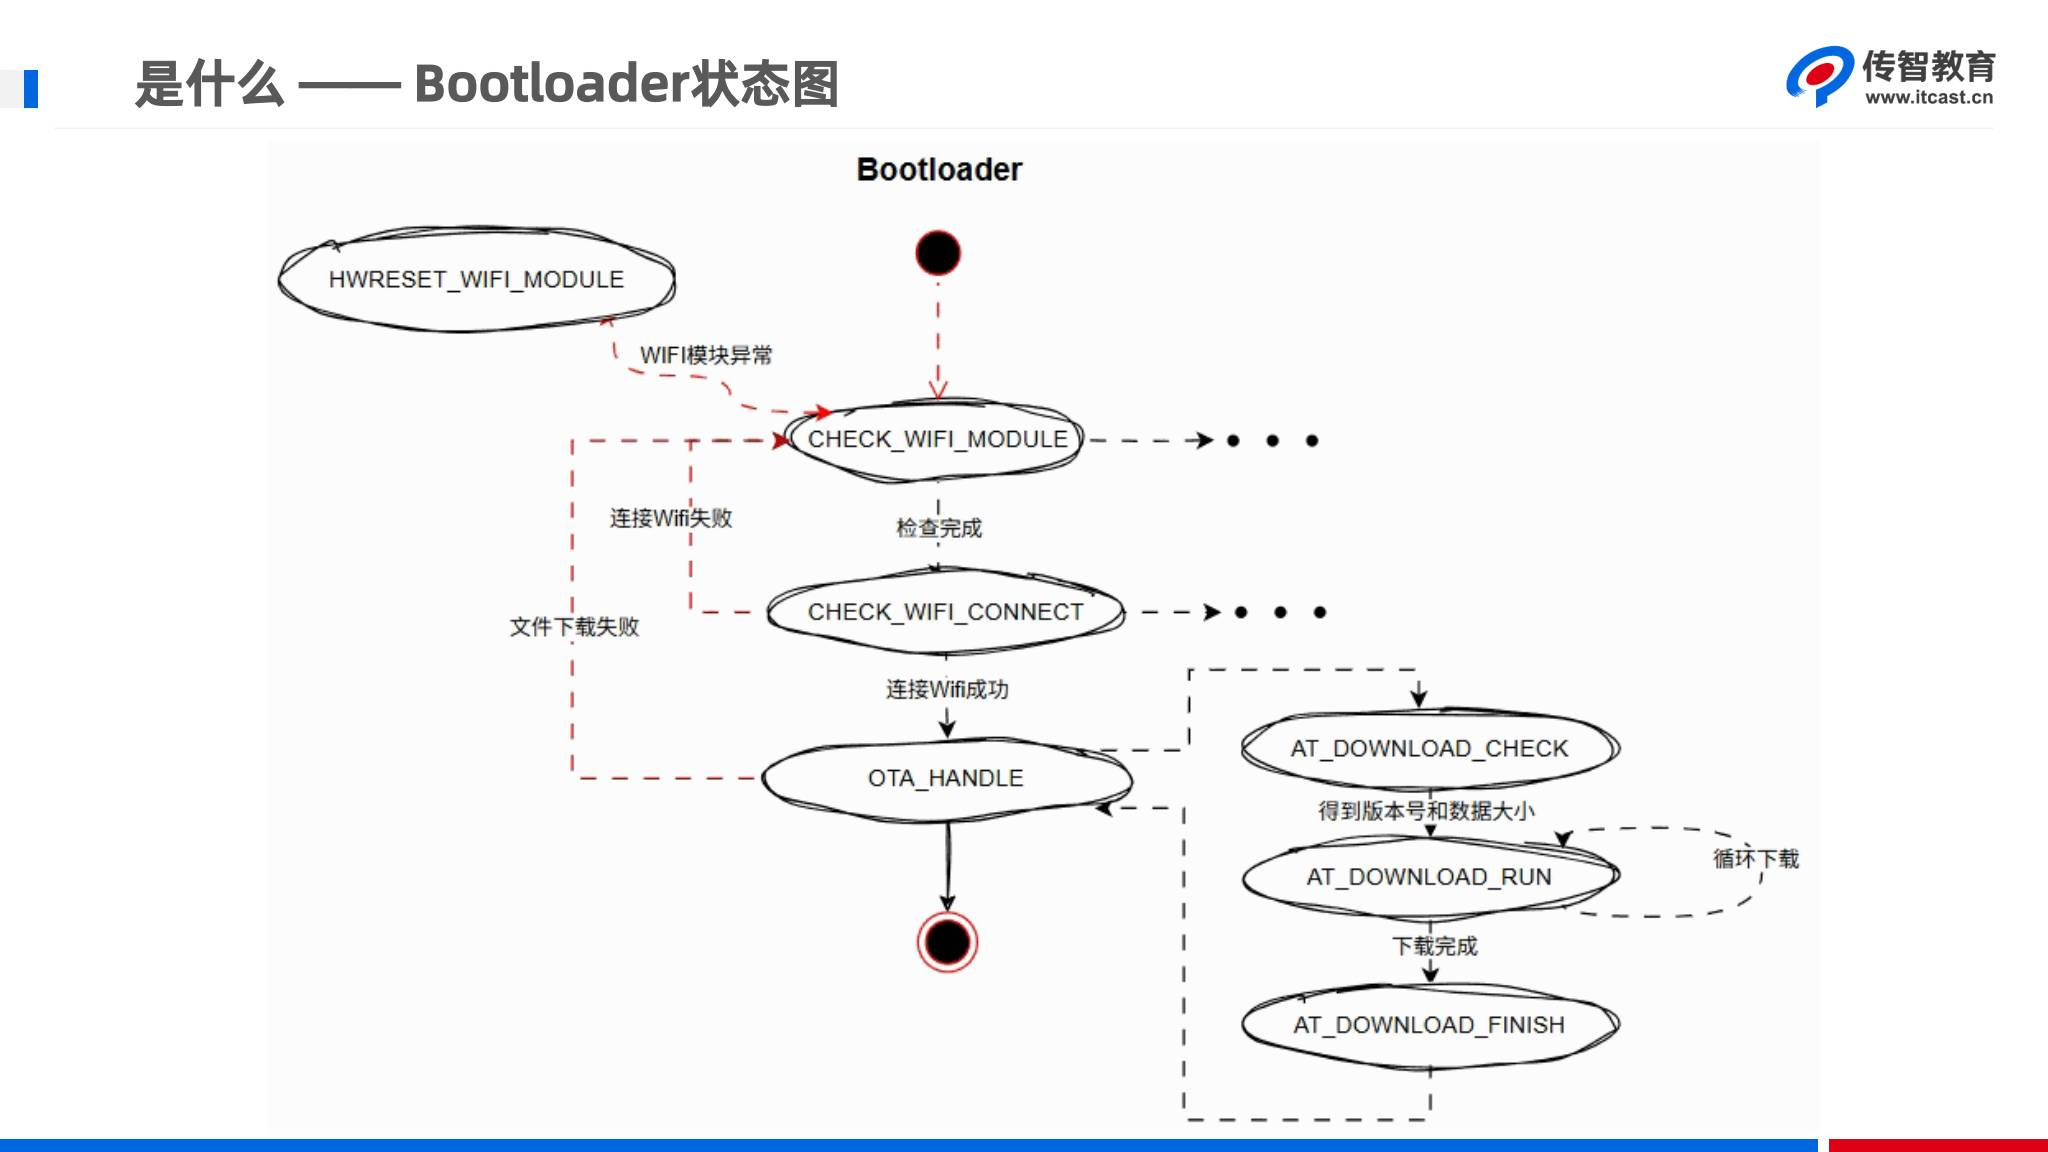

*讲义第73页：Bootloader侧进一步负责联网、处理新固件及跳转。完整下载实现留到第10篇。*

Bootloader侧的完整职责是：判断升级条件，准备通信，获取升级信息，下载新包到暂存区，检查完整性，替换App，并按流程处理升级结果和启动。

**本篇只利用Bootloader图理解职责。** 有限状态机既可用于App，也可用于Bootloader；两者的状态变量和运行时上下文独立。App里保存的普通全局变量在主控复位后不会自动成为Bootloader的可靠输入，需要由后续流程重新获取，或通过明确的持久化参数传递。


## 6. 主状态、子状态与通信结果三层不要混用

配套App有六个主状态：

```c
typedef enum {
    CHECK_WIFI_MODULE = 0,
    CHECK_WIFI_CONNECT,
    OTA_HANDLE,
    HWRESET_WIFI_MODULE,
    WIFI_WORK_DONE,
    WIFI_WORK_ERROR
} WifiWorkState_t;
```

其中前三个主状态各调用一个子流程函数：

| 主状态 | 子流程入口 | 工作内容 |
|---|---|---|
| `CHECK_WIFI_MODULE` | `CheckWifiModuleWork()` | AT软复位、关闭回显、设置Station模式 |
| `CHECK_WIFI_CONNECT` | `CheckWifiConnect()` | 查询是否已连接，否则连接指定热点 |
| `OTA_HANDLE` | `HandleOTA()` | 请求OneNET升级任务信息 |
| `HWRESET_WIFI_MODULE` | `HwresetWifiModule()` | EN硬件复位与恢复计数 |
| `WIFI_WORK_DONE` | 停止推进 | 本轮查询完成，等待后续用户操作 |
| `WIFI_WORK_ERROR` | 停止推进 | 硬件恢复机会用尽 |

前两个子流程内部还可以有自己的状态。例如模块检查按 `AT_RST → AT_E0 → AT_CWMODE_STA` 推进。

讲义图用 `ATE0`、`AT_CWMODE_1`、`AT_CWJAP_CHECK`、`AT_CWJAP_SSID_PWD` 表达含义；最终源码中可见 `AT_E0`、`AT_CWMODE_STA`、`AT_CWJAP_STATUS`、`AT_CWJAP_CONNECT`。**图和代码的词面可以不同，操作顺序与转换语义必须对应。**

通信结果用另一个枚举 `WifiCommState_t` 表示，取值是 `WIFI_COMM_WAIT`、`WIFI_COMM_OK`、`WIFI_COMM_FAIL`。它回答“这个子流程本次推进到了什么结果”，不能拿主状态枚举代替。


## 7. 三态返回值：WAIT必须留在原状态

子流程不是简单的bool接口，而是三态接口：

| 返回值 | 含义 | 主状态机如何处理 |
|---|---|---|
| `WIFI_COMM_WAIT` | 操作尚未完成，可能正在等响应 | 保持当前主状态，尽快返回调度器 |
| `WIFI_COMM_OK` | 本子流程全部完成 | 进入下一个主状态 |
| `WIFI_COMM_FAIL` | 已确认失败或超时，交由上层恢复 | 转入对应回退状态 |

正确判断：

```c
commState = CheckWifiModuleWork();
if (commState == WIFI_COMM_OK) {
    wifiState = CHECK_WIFI_CONNECT;
} else if (commState == WIFI_COMM_FAIL) {
    wifiState = HWRESET_WIFI_MODULE;
}
/* WAIT：不改wifiState，本次任务返回 */
```

下面这种写法会把WAIT也判为失败：

```c
/* 错误示例：不要采用 */
if (commState == WIFI_COMM_OK) {
    wifiState = CHECK_WIFI_CONNECT;
} else {
    wifiState = HWRESET_WIFI_MODULE;
}
```

任务每2 ms进入一次，不代表网络操作必须2 ms完成。等待期间再次调用相同子流程，是为了继续检查接收状态和超时；具体AT驱动还要记住“这一条是否已经发过”，避免每次回调重新发出同一命令。09篇再实现这种子状态配合。


## 8. 内置与外置Flash：新包先放在哪里

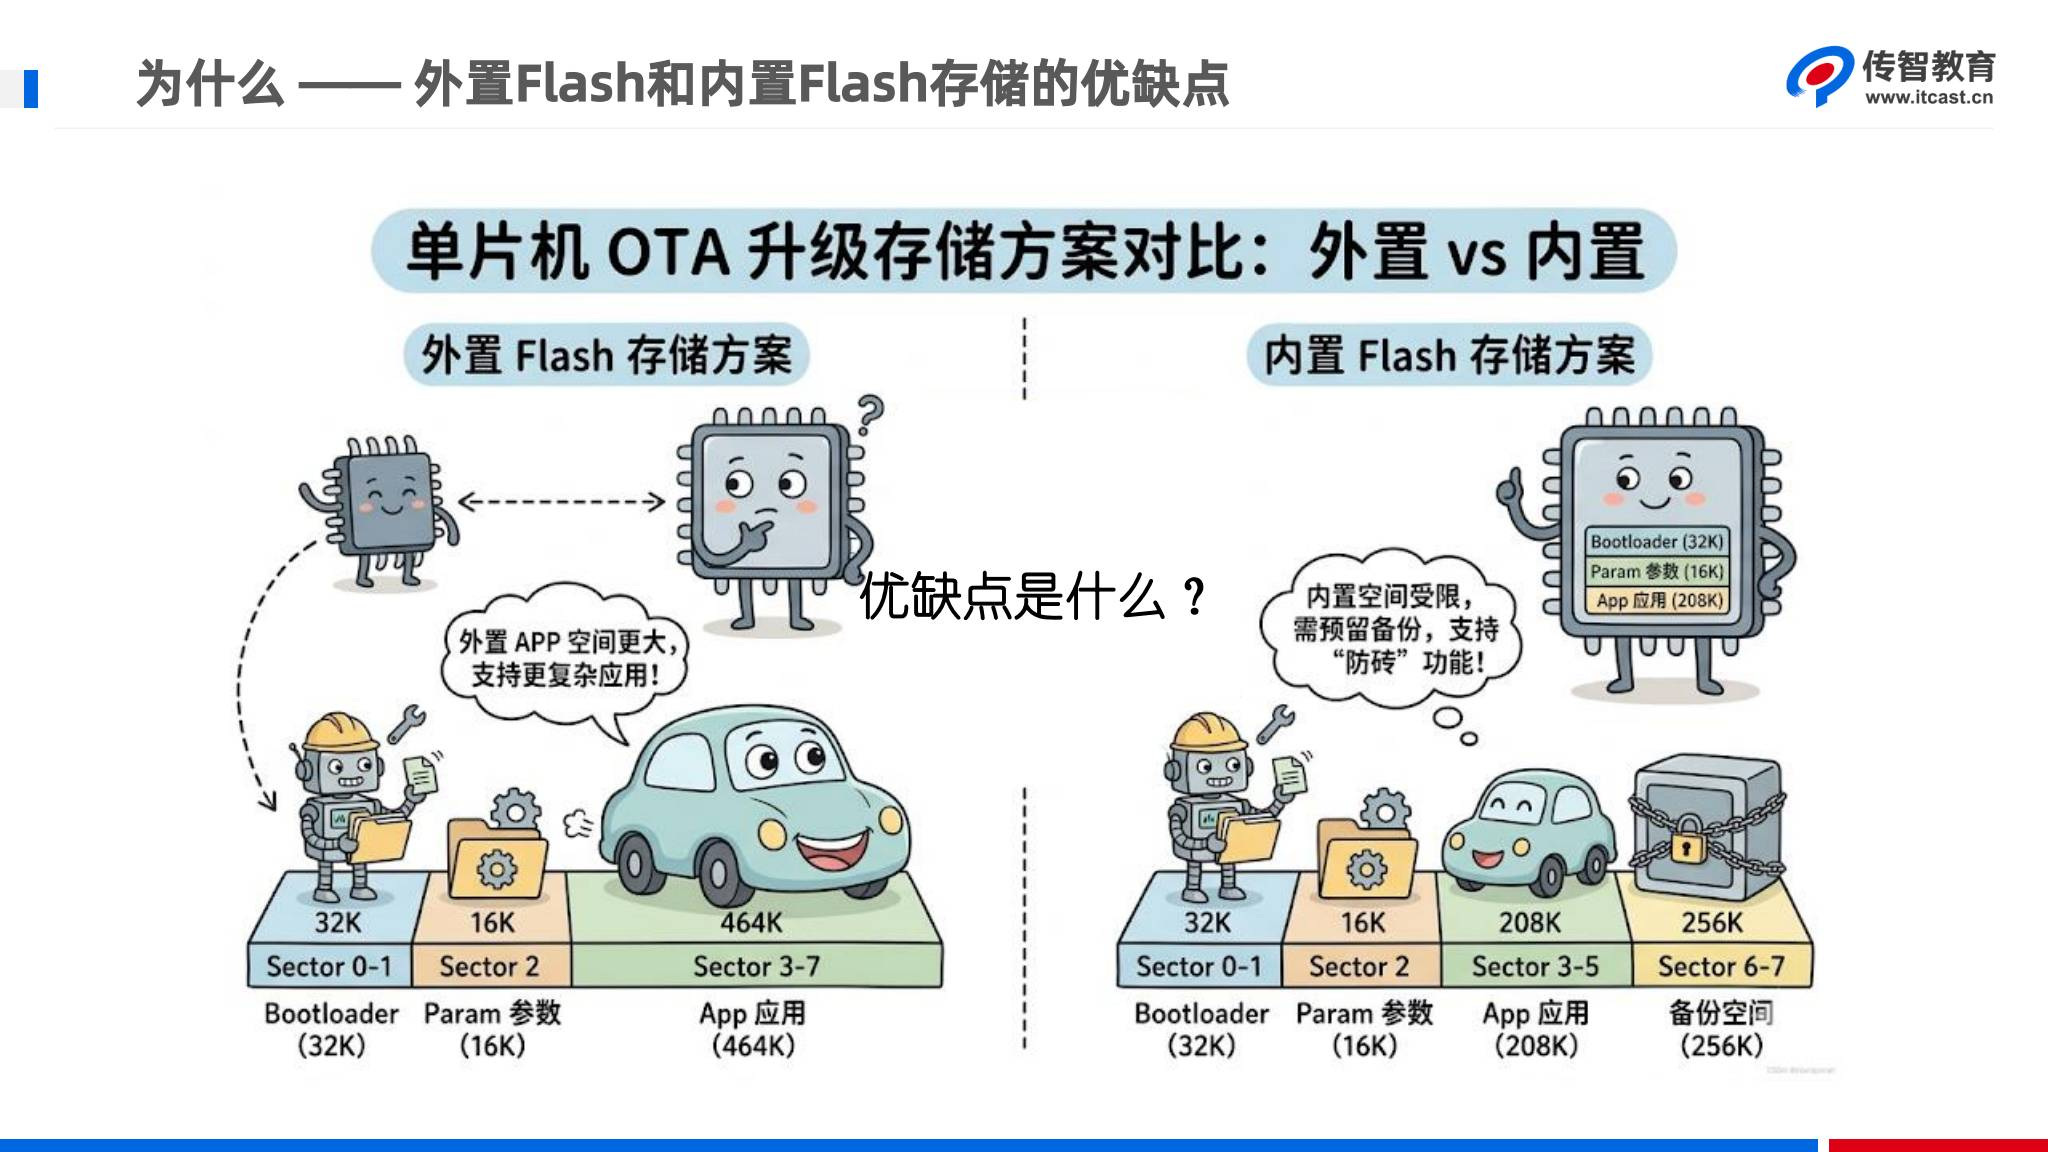

*讲义第74页：512 KiB内置Flash的两种分配思路。外置方案也把App放在主控内置Flash运行，外置芯片用于暂存下载的新包。*

| 比较项 | 外置Flash暂存 | 内置Flash暂存 |
|---|---|---|
| 新固件临时保存位置 | SPI等接口连接的外部Flash | MCU内部独立Backup区域 |
| 本课示例App可用空间 | 464 KiB | 208 KiB |
| 额外硬件 | 需要Flash芯片和连接 | 无需新增暂存芯片 |
| 驱动工作 | 要实现外置Flash通信、擦写和搬运 | 使用内置FMC擦写 |
| 主要约束 | 器件成本、驱动和读写时序 | 内部容量被暂存区占用 |
| 本课选择 | 用于理解与比较 | 实际采用此方案 |

为什么需要暂存区？网络下载可能中断。如果边下载边覆盖正在使用的App，一旦只写入半包就断电，App很可能无法正常启动。先把完整新包下载到独立区域，再做校验和替换，能把网络中断的影响限制在暂存阶段。

不过，**有Backup区并不等于已经实现A/B双槽或自动回滚。** 本课Backup保存待安装的新包，最终仍要覆盖App。覆盖阶段的断电恢复、重复搬运和新App运行确认，需要额外机制；不能仅凭图里“防砖”字样就认为所有时刻都安全。


## 9. 内置Flash地址表与容量计算

配套 `Common/store_app.h` 定义的总容量为 `0x80000`，即512 KiB；本笔记中的KiB按1024字节计算。

| 分区 | 起始地址 | 最后一个字节地址 | 容量 | 作用 |
|---|---|---|---:|---|
| Bootloader | `0x08000000` | `0x08007FFF` | 32 KiB | 启动、升级和跳转 |
| Param | `0x08008000` | `0x0800BFFF` | 16 KiB | 当前版本、升级标志等 |
| App | `0x0800C000` | `0x0803FFFF` | 208 KiB | 当前应用程序 |
| Backup | `0x08040000` | `0x0807FFFF` | 256 KiB | 暂存下载的新固件 |

```text
512 KiB = 32 KiB + 16 KiB + 208 KiB + 256 KiB
APP_SIZE = 512 KiB - 32 KiB - 16 KiB - 256 KiB
         = 208 KiB = 212992字节 = 0x34000
```

对应常量关系：

```c
#define FLASH_SIZE       0x80000
#define BOOTLOADER_SIZE  (32 * 1024)
#define PARAMETER_SIZE   (16 * 1024)
#define BACKUP_SIZE      (256 * 1024)
#define APP_SIZE         (FLASH_SIZE - BOOTLOADER_SIZE \
                         - PARAMETER_SIZE - BACKUP_SIZE)
#define PARAM_ADDR       0x08008000
#define APP_ADDR         0x0800C000
#define BACKUP_ADDR      0x08040000
#define VECTOR_OFFSET    0xC000
```

这里的代码用于集中展示分区关系，宏名与配套工程对应。**允许安装的新App上限受App区208 KiB约束**，不能因为Backup有256 KiB，就接受一个240 KiB的App镜像。

该头文件还有 `FLASH_PAGE_SIZE = 0x400`。这是本工程使用的1 KiB逻辑块参数，不能把它误当成芯片所有物理扇区的擦除粒度。实际擦除仍要依据GD32F407扇区布局，前02篇已经介绍其非等大扇区。


## 10. App链接地址、向量表和分区必须一致

App放在 `0x0800C000`，需要同时核对：

1. **链接起点**：App编译生成的程序从 `0x0800C000` 布局。
2. **向量表偏移**：App运行时，把中断向量表指向Flash基址加 `0xC000`。
3. **Bootloader跳转地址**：从 `APP_ADDR` 读取初始栈指针和复位入口。
4. **镜像长度**：新bin不得越过App区末尾进入Backup。

配套 `Common/iap_driver.c` 使用：

```c
nvic_vector_table_set(NVIC_VECTTAB_FLASH, VECTOR_OFFSET);
__enable_irq();
```

这解释了为什么“能跳到main”和“中断能正常工作”还要分别验证。没有迁移向量表时，中断可能仍进入Bootloader侧地址。

**随包工程核对发现的差异：** App的 `Project/GD32F407.uvprojx` 中IROM起点为 `0x0800C000`，但大小仍为 `0x80000`；压缩包中生成过的 `Objects/GD32F407.sct` 也声明：

```text
LR_IROM1 0x0800C000 0x00080000
ER_IROM1 0x0800C000 0x00080000
```

这并没有按208 KiB分区限制App。如果复现本篇的内置暂存布局，应在工程目标内存配置/实际生效的scatter文件中把App IROM范围收紧为：

```text
Start: 0x0800C000
Size : 0x00034000
```

这是根据分区核对提出的配置修正，**不是声称课程包已经这样配置**。若启用了自定义scatter，要修改真正参与链接的文件，不能只改一个未生效的界面字段。重新编译后检查链接映射和bin大小，确保代码、只读数据及加载映像都在允许范围。本次仅做了源码与工程文件的静态核对，未运行Keil编译。


## 11. 工程入口与协作式任务调度

本篇主要阅读 `06_GD32F407_OTA_App`：

| 文件 | 本阶段关注点 |
|---|---|
| `User/main.c` | 向量表处理、基础外设初始化、主循环 |
| `User/tasks.c` | 初始化三个App模块、任务周期、挂起恢复 |
| `App/App_Wifi.c` | 新版本信息与Wi-Fi主状态机 |
| `App/App_OLED.c` | 读取参数、绘制版本信息 |
| `App/App_Keys.c` | 按键事件、模拟新版本、长按入口 |
| `Common/store_app.*` | 分区、版本参数和升级标志 |
| `Common/wifi_drv.*` | EN控制与AT通信驱动接口 |

主程序先进行IRQ相关初始化和基础外设配置，再调用 `Task_init()`；其中初始化OLED、按键和Wi-Fi模块。主循环持续调用 `Task_exec_handler()`，定时中断每1 ms调用 `Task_switch_handler()`。

配套任务表的实际值：

```c
Task_t task_list[] = {
    {TASK_STATE_STOP, 200, 200, App_OLED_Task},  /* index 0 */
    {TASK_STATE_STOP,  10,  10, App_Keys_Task},  /* index 1 */
    {TASK_STATE_STOP,   2,   2, App_Wifi_Task}   /* index 2 */
};
```

| 任务 | 周期 | 目的 |
|---|---:|---|
| OLED | 200 ms | 更新屏幕缓存与显示 |
| 按键 | 10 ms | 读取按键事件 |
| Wi-Fi | 2 ms | 频繁推进通信状态机 |

`main.c` 某处注释提到OLED 100 ms，但任务表是200 ms，复现以实际表为准。

这不是RTOS线程：1 ms中断只递减计数并把任务标为RUN，真正的回调在main里依次执行。某个回调耗时太长，其他任务就会延迟。`HwresetWifiModule()` 内有100 ms阻塞延时，所以这套课程框架也并非每一步都完全无阻塞；不要把“Wi-Fi周期2 ms”理解成所有动作都能保持2 ms实时响应。

`Task_suspend(2)` 会挂起Wi-Fi任务。调度器在回调返回后，仅当任务仍为RUN才把它改回STOP，因此不会覆盖回调刚设定的SUSPEND状态。


## 12. 新版本元数据：定义一次，其他模块只声明

App查询到新任务后，需要让OLED和按键知道有可升级的信息。课堂先用两个全局变量打通模块间的数据通路：

```c
/* App_Wifi.c：拥有存储空间的定义 */
char g_otaVerNo[32] = "";
uint32_t g_otaBinSize = 0;
```

共享头文件中使用：

```c
/* 声明，用来引用已有变量 */
extern char g_otaVerNo[32];
extern uint32_t g_otaBinSize;
```

`extern` 只是声明，不再分配一份新的同名存储。不能把带初始化的定义复制到每个头文件包含点，否则可能发生重复定义。

初始大小为0，代表还没有可用于显示的新固件信息。版本字符串是云端返回的目标版本，如 `v2.3`。课堂先通过按键写入这两个值，验证显示链路；真实HTTP返回的任务ID、MD5等由后续实现处理。

参数区保存的是跨复位仍要保留的配置；上述全局变量是本次App运行期间的信息。`InitSysParam()` 会读取和检查参数，配套实现使用magic、CRC等判断参数是否有效，并按编译版本宏处理当前软件版本。它并没有自动提供双份参数备份或完整断电事务。


## 13. 用统一接口判断是否有新版本

OLED和升级入口都调用 `App_Wifi_GetNewVersion()`，避免各自写一份判断规则。以下为配套源码函数，保留课堂接口：

```c
bool App_Wifi_GetNewVersion(char* newVersion, uint32_t* newBinSize){
    // 判断两个参数指针是否为NULL
    if(newVersion == NULL || newBinSize == NULL){
        return false;
    }

    // 如果没有新版本
    if(g_otaBinSize == 0) return false;
    
    // 获取当前版本
    char curVersion[32] = "";
    GetSoftwareVersionParam(curVersion);

    // 比较新版本g_otaVerNo, 相同则返回false
    if(strcmp(g_otaVerNo, curVersion) == 0){
        return false;
    }

    // 复制新版本号
    strcpy(newVersion, g_otaVerNo);
    // 复制新版本固件大小
    *newBinSize = g_otaBinSize;
    
    return true;
}
```

按代码顺序解释：

1. 调用方必须提供版本输出缓冲区和大小输出指针。
2. `g_otaBinSize == 0` 时返回false，屏幕不显示升级提示。
3. 通过 `GetSoftwareVersionParam()` 获取当前软件版本。
4. `strcmp() == 0` 表示字符串相同，不需要提示。
5. 不相同时，把目标版本和大小复制给调用方，返回true。

**这只是“版本字符串是否不同”，没有实现版本大小排序。** 当前 `v2.0`、目标 `v1.0` 也会被判为不同。需要禁止降级时，应另加版本策略；不要把strcmp当成语义化版本比较。

还有一个需认识的接口限制：`strcpy()` 不知道调用方容量。全局版本缓冲区是32字节，而OLED中的 `newVersion` 只有16字节。课堂短版本能工作，不代表任意云端字符串都安全。后续完善时应统一版本长度上限，给拷贝函数传入容量，并预留结尾 `'\0'`。本篇忠实保留原接口，未把改进后的接口冒充课程代码。

返回false时，不应继续使用输出参数的旧值；调用方要以返回结果决定是否显示、是否允许进入升级。


## 14. OLED：先画当前版本，再决定是否显示升级区

`App_OLED_Task()` 先清空显示缓存，获取当前版本，再根据新版本接口决定后半屏内容。配套关键函数如下：

```c
void App_OLED_Task(void) {
    
    OLED_Clear(0); // 先把屏幕全部清空

    // Cur Version: v1.0 当前版本
    GetSoftwareVersionParam(version);
    sprintf(strBuf, "Cur Ver: %s", version);   
    
    OLED_ShowString(0, 0, strBuf, 16, 1);

    // 如果新版本和当前版本不同, 才需要提示升级
    if(!App_Wifi_GetNewVersion(newVersion, &newBinSize)){
        // 没有新版本信息
        OLED_Refresh(); // 将缓冲区内容刷新到屏幕
        return;
    }
    // 绘制横线 -------------------------------------
    OLED_DrawLine(0, 16, 128, 16, 1);
    // New Version: v1.2 新版本
    sprintf(strBuf, "New Ver: %s", newVersion);
    OLED_ShowString(0, 18, strBuf, 16, 1);
    // BinSize: xxxx
    sprintf(strBuf, "BinSize: %d", newBinSize);
    OLED_ShowString(0, 34, strBuf, 16, 1);
    // 绘制横线 -------------------------------------
    OLED_DrawLine(0, 50, 128, 50, 1);
    // OTA: 开始OTA
    OLED_ShowString(0, 56, "Long Press To Update", 8, 1);

    OLED_Refresh(); // 将缓冲区内容刷新到屏幕

}
```

屏幕组织：

| 内容 | 坐标/字体 | 显示条件 |
|---|---|---|
| `Cur Ver: ...` | x=0，y=0，16号字 | 始终显示 |
| 第一条横线 | y=16 | 有新版本 |
| `New Ver: ...` | x=0，y=18，16号字 | 有新版本 |
| `BinSize: ...` | x=0，y=34，16号字 | 有新版本 |
| 第二条横线 | y=50 | 有新版本 |
| `Long Press To Update` | x=0，y=56，8号字 | 有新版本 |

`OLED_Clear(0)` 先清缓存，`OLED_Refresh()` 才把缓存送到屏幕。因此**无新版本分支也必须Refresh再return**，否则缓存虽然变了，屏上仍可能保留之前的新版本提示。

任务每200 ms刷新，不需要按键处理函数直接重画整屏：按键只改数据，OLED任务下一次自动读取和呈现。这个分工也方便后续把假数据替换成真实HTTP结果。

代码中的 `sprintf`、16字节版本缓冲和32字节字符串缓冲都依赖输入长度约束。这里重点学习绘制次序和模块接口，复用到实际产品时应检查格式化输出容量；大小作为无符号32位值时，也应使用与目标编译器类型匹配的格式。


## 15. 按键配合：先用假数据验证界面，再保留升级入口

按键任务调用 `bsp_keys_adv_get()` 获取事件；0表示没有事件，低4位表示按键编号：

```c
uint8_t value = bsp_keys_adv_get();
if (value == 0x00) return;
uint8_t key = value & 0x0F;
```

课程按事件值识别双击和长按：

| 条件 | 课堂含义 |
|---|---|
| `value > 0xE0 && value < 0xF0` | 双击事件 |
| 进入非双击分支后 `value > 0xF0` | 长按事件 |
| 其余相应事件 | 短按 |

这是本工程按键库的编码约定，不是C语言或所有按键库通用的规则。

视频35用按键4模拟发现新固件：

```c
/* 配套App_Keys.c的按键4非双击分支 */
strcpy(g_otaVerNo, "v2.3");
g_otaBinSize = 12345;
```

预期过程：刚启动只有当前版本；课堂短按4后，下一次OLED刷新显示 `New Ver: v2.3`、`BinSize: 12345` 和长按提示。配套源码把这两句放在按键4的非双击else里，因此**长按4同样可能设置假数据**，并非严格只有短按4允许触发。

按键1长按调用：

```c
if (value > 0xF0) {
    App_Wifi_Update();
}
```

该入口最终应先重新检查有效新版本，再写升级标志、复位回Bootloader。第36段结束时主要搭好主框架；完整配套包已含后续 `App_Wifi_Update()` 实现，详细写参数和重启过程放在09篇。测试本篇界面时不要把“长按函数被调用”当成“已经下载并升级完成”。

课堂假数据验证的是“共享数据 → 判断接口 → OLED → 用户入口”链路。准备接入真实查询后，要撤掉或明确隔离按键4的假数据写入，避免它覆盖真实任务信息。


## 16. App主状态机：完整主干代码与流转表

以下为配套 `App_Wifi.c` 的完整主任务函数。它保留第36段搭出的三阶段推进和恢复分支；DONE/ERROR里的打印和 `Task_suspend(2)` 是**最终配套工程**的停止处理，第36段搭框架时先用空分支或日志验证流转。

```c
void App_Wifi_Task(void){ // 2ms间隔调用
    static WifiWorkState_t wifiState = CHECK_WIFI_MODULE;
    static uint8_t hwresetCount = 0;
    WifiCommState_t commState;

    switch (wifiState) {
        case CHECK_WIFI_MODULE:     // RST软重置&检查Wifi模块是否存在
            commState = CheckWifiModuleWork();
            if(commState == WIFI_COMM_OK){
                wifiState = CHECK_WIFI_CONNECT; // 状态切换(流转)
            }else if(commState == WIFI_COMM_FAIL){
                wifiState = HWRESET_WIFI_MODULE; // 状态切换(流转)
            }
            break;
        case CHECK_WIFI_CONNECT:    // 检查Wifi连接状态(如果没连接, 则连接)
            commState = CheckWifiConnect();
            if(commState == WIFI_COMM_OK){
                wifiState = OTA_HANDLE; // 状态切换(流转)
            }else if(commState == WIFI_COMM_FAIL){
                wifiState = CHECK_WIFI_MODULE; // 状态切换(流转)
            }
            break;
        case OTA_HANDLE:            // 获取新版本信息
            commState = HandleOTA();
            if(commState == WIFI_COMM_OK){
                wifiState = WIFI_WORK_DONE; // 状态切换(流转)
            }else if(commState == WIFI_COMM_FAIL){
                wifiState = CHECK_WIFI_MODULE; // 状态切换(流转)
            }
            break;
        case HWRESET_WIFI_MODULE:   // 硬件重置Wifi模块
            if(hwresetCount < 3){
                printf("Hard Reset Wifi Module, Count: %d\r\n", hwresetCount);
                HwresetWifiModule();
                hwresetCount++;
                wifiState = CHECK_WIFI_MODULE; // 状态切换(流转)
            }else {
                wifiState = WIFI_WORK_ERROR; // 状态切换(流转)
                hwresetCount = 0;   // 恢复重置次数
            }
            break;
        case WIFI_WORK_DONE:        // Wifi工作完成, 等待用户操作
            printf("4. Wifi Work Done\r\n");
            Task_suspend(2);
            break;
        case WIFI_WORK_ERROR:       // Wifi工作错误, 等待用户操作
            printf("5. Wifi Work Error\r\n");
            Task_suspend(2);
            break;
    }

}
```

对应规则：

| 当前主状态 | WAIT | OK | FAIL |
|---|---|---|---|
| 检查模块 | 原地等待 | 检查Wi-Fi连接 | 硬件复位 |
| 检查Wi-Fi连接 | 原地等待 | 获取升级信息 | 回检查模块 |
| 获取升级信息 | 原地等待 | DONE | 回检查模块 |

硬件复位分支另按计数执行：

```text
hwresetCount初值0
  第1次进入恢复分支：0 < 3，打印Count: 0，复位，计数变1
  第2次进入恢复分支：1 < 3，打印Count: 1，复位，计数变2
  第3次进入恢复分支：2 < 3，打印Count: 2，复位，计数变3
  再次失败后进入分支：3不小于3，转ERROR，计数清零
```

所以日志0、1、2是**三次复位前的计数值**，不是“只重置了两次”。进入ERROR的那次不再执行第4次硬件复位。

`static WifiWorkState_t wifiState` 和 `static uint8_t hwresetCount` 只初始化一次，函数返回后仍保存值。若把它们改成普通局部变量且每次初始化，任务就会每次回到第一个状态，无法推进。

DONE只表示本轮App通信流程完成，并不表示升级完成，更不等于OneNET业务码201。界面和按键还要继续工作，等待用户确认。


## 17. 用桩函数验证主框架：先隔离网络变量

第36段先让子流程返回固定状态，测试主状态机规则。此时可以把三个子流程暂时写成下面形式，**用于课堂框架测试，不能与原工程同名正式实现同时保留**：

```c
WifiCommState_t CheckWifiModuleWork(void) {
    printf("1. Check Wifi Module Work\r\n");
    return WIFI_COMM_WAIT;
}

WifiCommState_t CheckWifiConnect(void) {
    printf("2. Check Wifi Connect\r\n");
    return WIFI_COMM_WAIT;
}

WifiCommState_t HandleOTA(void) {
    printf("3. Handle OTA\r\n");
    return WIFI_COMM_WAIT;
}
```

测试时逐项修改返回值，每种场景重新复位，避免上次保留的static状态影响判断：

| 场景 | 模块检查 | 联网 | OTA信息 | 预期 |
|---|---|---|---|---|
| A 等待 | WAIT | 不会进入 | 不会进入 | 日志一直是1，无复位 |
| B 第一阶段通过 | OK | WAIT | 不会进入 | 先1，再持续2 |
| C 前两阶段通过 | OK | OK | WAIT | 先1、2，再持续3 |
| D 全通过 | OK | OK | OK | 1 → 2 → 3 → DONE |
| E 模块持续失败 | FAIL | 不会进入 | 不会进入 | 三次硬复位，随后ERROR |
| F 联网失败 | OK | FAIL | 不会进入 | 在1、2之间重复 |
| G OTA信息失败 | OK | OK | FAIL | 在1、2、3之间重复 |

D场景若用最终配套的 `Task_suspend(2)`，DONE只打印一次后Wi-Fi任务挂起；如果用课堂阶段的日志空转分支，日志可能反复出现。应根据自己采用的版本判断。

**F/G不会自动被“三次硬复位上限”终止。** 因为它们只回到模块检查；如果模块检查每次都OK，就不会进入硬复位分支，`hwresetCount` 也不会增加。视频末尾确实观察到 `1、2、3` 循环，并说明本阶段暂不加更多重试控制。实际产品若需总超时、联网重试上限和退避，应另行设计。

桩测试通过说明转换规则符合预期，不能证明Wi-Fi连上了、Token有效、HTTP解析正确或固件能写入Flash。


## 18. 测试节奏、日志与Keil索引问题

正式Wi-Fi任务周期2 ms，若每次调用都输出日志，每秒理论上可进入约500次，串口很快刷屏，打印本身还会改变时序。

视频中测试主框架时，临时把Wi-Fi任务周期调长到约100—200 ms，方便肉眼观察状态。调整时同时核对任务表中的初始计数和周期，测试后恢复正式值：

```text
测试观察：Wi-Fi task_cnt / task_period 临时设100或200
正式框架：Wi-Fi task_cnt = 2，task_period = 2
```

更适合后续使用的日志策略，是只在状态变化、重试、超时和终态时打印；不要在每个WAIT回调都刷整行数据。

视频还遇到Keil中F12不能跳到类型定义的问题。处理顺序：

1. 确认包含了定义 `WifiCommState_t` 的正确头文件。
2. 先编译，区分真实编译错误和编辑器索引错误。
3. 若编译通过但跳转失效，重新扫描源码/更新Source Browser信息，再尝试F12。
4. 必要时关闭重开文件或工程。

**索引失效不等于类型不存在；能跳转也不等于链接和固件布局正确。** 本笔记按配套源码核对了类型名，没有在当前机器复现Keil界面操作。


## 19. 联调清单与常见问题

建议按层次完成本阶段复现，以下均为待开发板验证的检查项：

1. **硬件层**：确认PB10/11与IO6/7交叉、GND共地、PB12接EN。
2. **基础工程层**：确认USART2初始化和接收配置真实生效，复位能重新看到ESP启动响应。
3. **参数层**：OLED可读出当前版本；版本来自参数初始化规则，与编译的版本宏一致。
4. **界面层**：假数据触发后显示新版本、大小和长按提示；无新版本分支刷新后没有旧内容残留。
5. **状态机层**：逐项验证WAIT、OK、FAIL及三次硬复位，记录状态序列。
6. **收尾**：恢复2 ms周期，撤销假返回值，保留需要的日志；后续再实现真实子状态。

| 现象 | 优先检查 |
|---|---|
| 一直停在状态1 | 是否仍是返回WAIT的桩；不要直接判硬件坏 |
| 每次调用都从状态1开始 | 主状态变量是否丢了static或被反复重置 |
| 没等到响应就反复硬复位 | 是否把WAIT写进普通else失败分支 |
| 重置日志0、1、2后ERROR | 正是三次恢复机会；不应再执行第4次 |
| OTA失败后一直1、2、3循环 | 本框架没有该路径的全局重试上限 |
| 界面还显示旧升级信息 | 无新版本分支是否Refresh，数据是否清理 |
| 版本号一长就异常 | 32/16字节容量不一致、strcpy/sprintf无长度限制 |
| App能运行但中断异常 | 链接起点与向量表偏移是否一致 |
| 208 KiB以上仍能链接 | 随包IROM大小过大，尚未按分区收紧 |
| Wi-Fi任务DONE后不再查询 | 最终工程已挂起任务2，需明确再次查询的入口 |

不要在主状态机失败时一次性修改所有层。先确认哪一步返回了什么，再沿该子流程检查，才能把接线、AT响应、网络和业务错误分开定位。


## 20. 知识自查、来源与后续衔接

| 自查题 | 应掌握的答案 |
|---|---|
| GD32哪一路串口控制ESP？ | USART2，PB10发、PB11收，接ESP的IO6/7 |
| PB12接哪里，做什么？ | 接EN，低100 ms再拉高做硬件复位 |
| WAIT时主状态要切换吗？ | 不切换，下次任务继续推进 |
| 为什么状态变量要static？ | 跨多次任务调用保存进度 |
| 208 KiB与256 KiB谁限制新App大小？ | 目标App区208 KiB；Backup更大不放宽安装上限 |
| Backup是不是自动回滚双槽？ | 不是，本课把它作为新包暂存区 |
| 屏幕无新版本时为何还Refresh？ | 把清理后的缓存送到屏幕，移除旧提示 |
| strcmp不同是否说明版本更高？ | 不说明，只表示字符串不同 |
| 三次硬复位是否限制所有失败？ | 只限制进入该分支的模块恢复路径 |
| 桩函数全OK说明什么？ | 主流程可达DONE，不证明真实联网或OTA完成 |
| 配套App链接配置有什么要核对？ | 起点正确但IROM大小过大，应按内置方案限制到0x34000 |

**课程来源：** 视频32—36完整自动字幕，讲义物理页70—74原图；配套 `06_GD32F407_OTA_App` 中 `App_Wifi.c`、`App_OLED.c`、`App_Keys.c`、`tasks.c`、`main.c`、`wifi_drv.*`、`store_app.*`、`iap_driver.c`；另对照Bootloader分区与跳转关系，以及App工程 `GD32F407.uvprojx` 和压缩包内的scatter文件。来源文件指纹、字幕末尾时间和图片信息保存在Notebook元数据中。

**下一篇09：** 把三个WAIT桩依次替换成真实模块检查、联网和版本检测子状态，解析OneNET任务信息，在用户确认后持久化升级标志并复位。**第10篇：** 继续完成Bootloader里的分片下载、校验、固件替换和结果处理。

本篇应留下的成果是：接线表、Flash布局、可解释的App状态转换、能用假数据验证的OLED/按键界面，以及明确的后续接口。网络下载和硬件测试尚需在对应阶段执行。
